# P717: Apple Stock Price Prediction — Master Notebook

## Business objective

Explore historical Apple stock data and evaluate forecasts for the next 30 trading sessions, a provisional interpretation of the project brief. These experiments use data ending in 2019 and do not produce current market forecasts or investment advice.

The supplied `Close` and `Adj Close` columns are distinct. The modeling target is the supplied `Close`; its source-specific adjustment convention and currency have not been verified.

## 1. Import libraries

Load the analysis and forecasting libraries. Thread limits keep the experiment computationally reasonable and apply only to this Python process.

Verified environment: Python 3.13.9, NumPy 2.5.1, pandas 2.3.3, matplotlib 3.10.6, seaborn 0.13.2, scikit-learn 1.7.2, statsmodels 0.14.5 and XGBoost 3.3.0. The statistical fits emitted nonfatal NumPy deprecation warnings in this environment.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

## 2. Load the dataset

The path check supports running this notebook with the project root or the `notebooks/` folder as the working directory. The CSV is read into `df`; the source file is not edited.

In [2]:
data_path = Path("data/raw/Dataset.csv")

if not data_path.exists():
    data_path = Path("../data/raw/Dataset.csv")

if not data_path.exists():
    raise FileNotFoundError("Dataset.csv was not found from the project root or notebooks folder.")

print("Loading:", data_path)
df = pd.read_csv(data_path)

Loading: ..\data\raw\Dataset.csv


## 4. Check the dataset structure

Check the number of rows and columns, field names, and data types before analysis. At this point `Date` is still the value read from the CSV.

In [3]:
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print("\nColumn data types:")
print(df.dtypes)

Dataset shape: (2011, 7)
Column names: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

Column data types:
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2011 entries, 0 to 2010
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2011 non-null   object 
 1   Open       2011 non-null   float64
 2   High       2011 non-null   float64
 3   Low        2011 non-null   float64
 4   Close      2011 non-null   float64
 5   Adj Close  2011 non-null   float64
 6   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 110.1+ KB


**Observation:** All seven columns contain 2,011 non-null values. `Date` is loaded as `object`; the five price columns are `float64`, and `Volume` is `int64`.

## 5. Descriptive statistics

`describe()` summarizes the numeric fields, including `Close` and `Adj Close` separately. These values describe the supplied period; they are not forecasts.

In [5]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,126.707469,127.827594,125.580258,126.741235,119.505548,5.949670e+07
std,50.483753,50.926301,50.124940,50.578369,52.438444,4.683856e+07
min,55.424286,57.085712,55.014286,55.790001,48.921928,1.136200e+07
25%,85.882858,86.717858,85.056427,86.202145,75.056679,2.758565e+07
50%,113.050003,114.190002,111.870003,113.050003,105.222908,4.346900e+07
75%,165.190002,167.409996,163.424995,165.245002,160.047111,7.471030e+07
max,291.119995,293.970001,288.119995,291.519989,289.522614,3.765300e+08


**Interpretation:** `Close` ranges from 55.79 to 291.52, while `Adj Close` ranges from 48.92 to 289.52. Their summary values differ, so they remain separate measures; these statistics describe the historical sample, not a forecast.

## 6. Check missing values and duplicate records

These checks report data-quality counts without removing or changing rows. Exact duplicate rows and repeated dates are checked separately.

In [6]:
df.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

**Observation:** No missing values were found in any column (0 missing values across all seven columns).

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


**Observation:** No exact duplicate rows were found (0 rows).

## 7. Convert dates and inspect chronological order

Create a parsed datetime column while keeping the original `Date` values. `errors="coerce"` marks unparseable nonmissing values as `NaT`, which lets us count and inspect them; it does not remove observations. The duplicate-date check uses successfully parsed dates, separate from exact-row duplicates.

In [8]:
df["Date_parsed"] = pd.to_datetime(df["Date"], errors="coerce")

parse_errors = df.loc[df["Date"].notna() & df["Date_parsed"].isna(), "Date"]
missing_dates = df["Date"].isna().sum()

print("Missing Date values:", missing_dates)
print("Nonmissing Date values that failed parsing:", len(parse_errors))
print("Unparsed Date examples:")
parse_errors.head()

Missing Date values: 0
Nonmissing Date values that failed parsing: 0
Unparsed Date examples:


Series([], Name: Date, dtype: object)

**Observation:** There are 0 missing `Date` values and 0 nonmissing dates that failed parsing. No rows were removed, and all dates parsed successfully.

### Check repeated dates and row order

Repeated dates can affect time-series summaries. Check parsed dates for repeats and verify whether valid dates increase in the CSV's existing row order; these checks leave the rows where they are.

In [9]:
valid_dates = df.loc[df["Date_parsed"].notna(), "Date_parsed"]

print("Duplicate parsed dates:", valid_dates.duplicated().sum())
print("Valid dates are increasing in the original row order:", valid_dates.is_monotonic_increasing)
print("Adjacent backwards date steps:", df["Date_parsed"].diff().lt(pd.Timedelta(0)).sum())
print("First parsed date:", valid_dates.min())
print("Last parsed date:", valid_dates.max())
print("Rows retained in df:", len(df))

Duplicate parsed dates: 0
Valid dates are increasing in the original row order: True
Adjacent backwards date steps: 0
First parsed date: 2012-01-03 00:00:00
Last parsed date: 2019-12-30 00:00:00
Rows retained in df: 2011


**Interpretation:** There are 0 repeated parsed dates. The valid dates increase in the original row order, with 0 backward steps. The data spans 2012-01-03 to 2019-12-30, and all 2,011 rows remain in that order.

## 8. Plot the historical closing price

Plot `Close` against the parsed date values in their original row order. The original `Date` text and all rows remain in `df`; any unparseable date will not have a usable position on the date axis and should be considered when interpreting the chart.

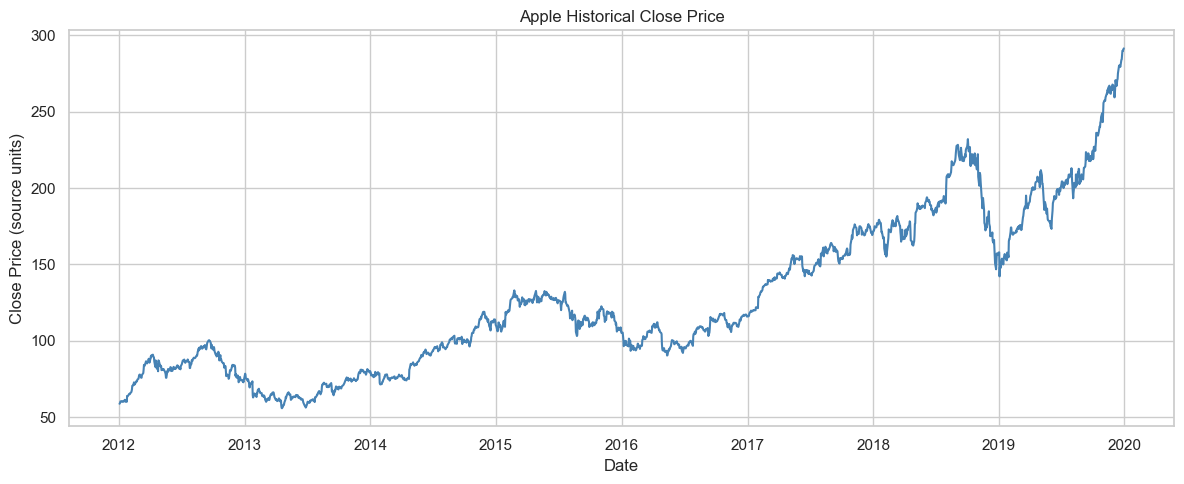

In [10]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
plt.plot(df["Date_parsed"], df["Close"], color="steelblue")
plt.title("Apple Historical Close Price")
plt.xlabel("Date")
plt.ylabel("Close Price (source units)")
plt.tight_layout()
plt.show()

**Chart interpretation:** `Close` rises overall across the period, with visible fluctuations, including a pronounced decline in late 2018 followed by recovery. The plot shows movement over time; it does not explain the causes.

## 9. Daily returns

A daily return measures the percentage change in Close from the previous trading observation. The first row has no previous price, so its return is missing.

In [11]:
df["Daily_Return"] = df["Close"].pct_change() * 100
print("Daily returns calculated:", df["Daily_Return"].notna().sum())
print("First return is missing:", pd.isna(df["Daily_Return"].iloc[0]))

Daily returns calculated: 2010
First return is missing: True


**Observation:** The first return is missing because there is no earlier row in this dataset.

### Summarize daily returns

The summary shows the center and spread of daily price changes.

In [12]:

# Summary statistics of daily returns
df["Daily_Return"].describe()


count    2010.000000
mean        0.092755
std         1.612388
min       -12.355795
25%        -0.675187
50%         0.071546
75%         0.957123
max         8.874137
Name: Daily_Return, dtype: float64

**Observation:** The mean Close return is approximately 0.093% and the standard deviation is approximately 1.61% per observed session.

### Plot the return distribution

A histogram shows how often returns fall into different ranges.

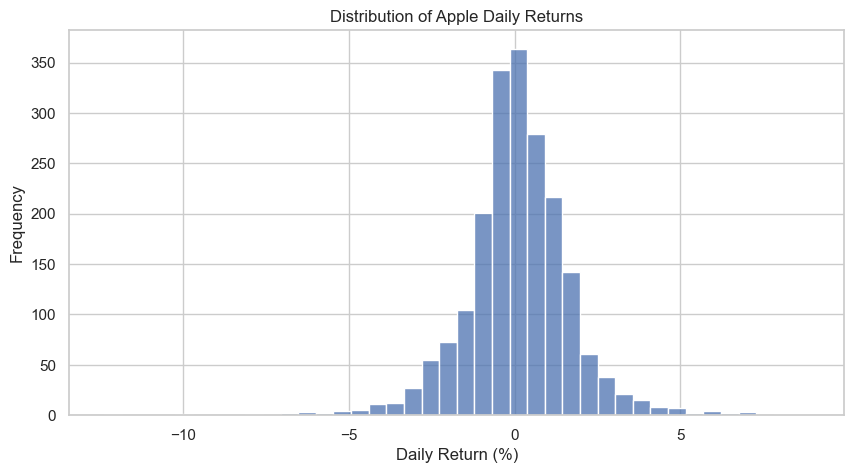

In [13]:

# Visualize the distribution of daily returns
plt.figure(figsize=(10, 5))

sns.histplot(df["Daily_Return"].dropna(), bins=40)

plt.title("Distribution of Apple Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.show()


**Observation:** Most daily changes are relatively close to zero, with a small number of larger positive and negative changes.

### Find extreme returns

The largest daily increase and decrease identify dates for further inspection; they do not establish why prices moved.

In [14]:
df.loc[[df["Daily_Return"].idxmin(), df["Daily_Return"].idxmax()],
       ["Date", "Daily_Return"]]

,Date,Daily_Return
265,2013-01-24,-12.355795
78,2012-04-25,8.874137


**Observation:** The largest increase is approximately 8.87% on 2012-04-25; the largest decline is approximately 12.36% on 2013-01-24.

## 10. Close and adjusted close

Close and Adj Close are distinct fields. Adjusted prices often account for events such as splits and dividends, but the supplied file does not document its provider or exact adjustment rules. The ratio shows how the two supplied columns relate.

For an example of an adjustment convention, see [Yahoo Finance’s explanation](https://in.help.yahoo.com/kb/adjusted-close-sln28256.html). This does not establish that Yahoo supplied this file.

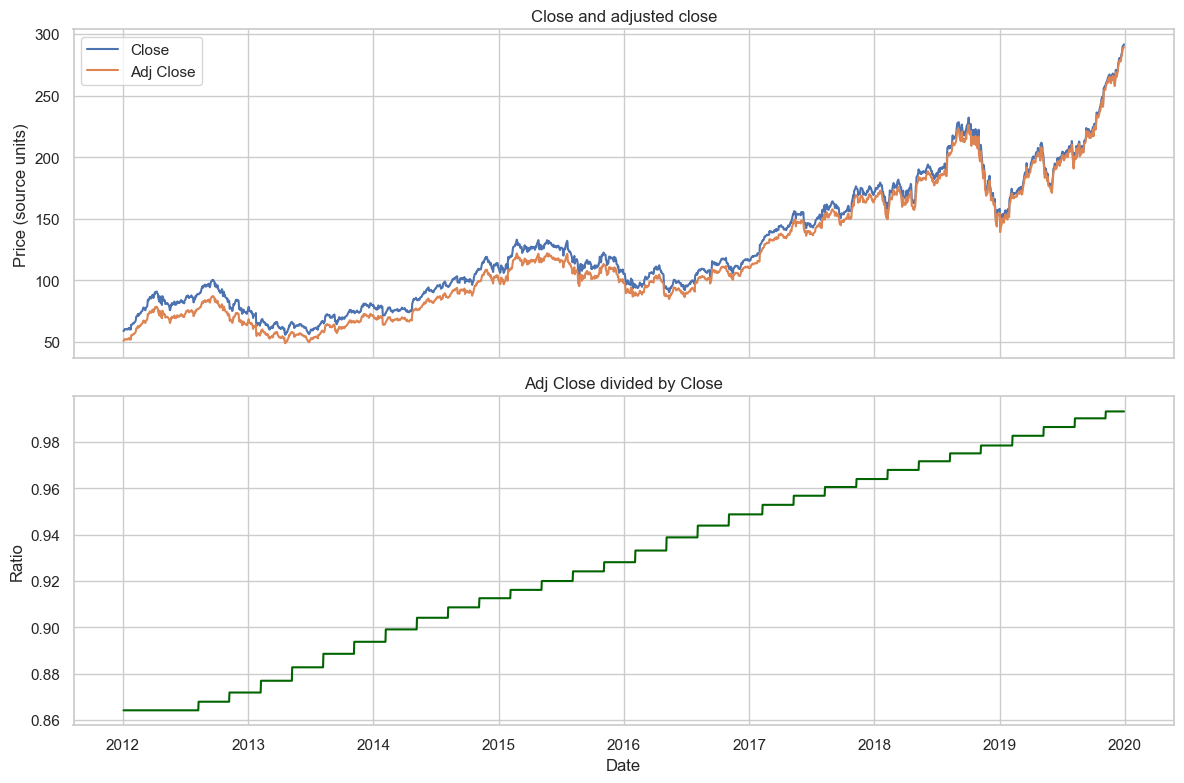

Rows where Close equals Adj Close: 0


In [15]:
df["Adjustment_Ratio"] = df["Adj Close"] / df["Close"]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(df["Date_parsed"], df["Close"], label="Close")
axes[0].plot(df["Date_parsed"], df["Adj Close"], label="Adj Close")
axes[0].set_title("Close and adjusted close")
axes[0].set_ylabel("Price (source units)")
axes[0].legend()
axes[1].plot(df["Date_parsed"], df["Adjustment_Ratio"], color="darkgreen")
axes[1].set_title("Adj Close divided by Close")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Ratio")
plt.tight_layout()
plt.show()

print("Rows where Close equals Adj Close:", (df["Close"] == df["Adj Close"]).sum())

**Observation:** Close and Adj Close differ in all 2,011 rows. The ratio varies over time; the file alone does not establish the cause of each change.

## 11. Moving averages

A moving average smooths short-term price changes. The 20- and 50-session averages use only the current and earlier observations.

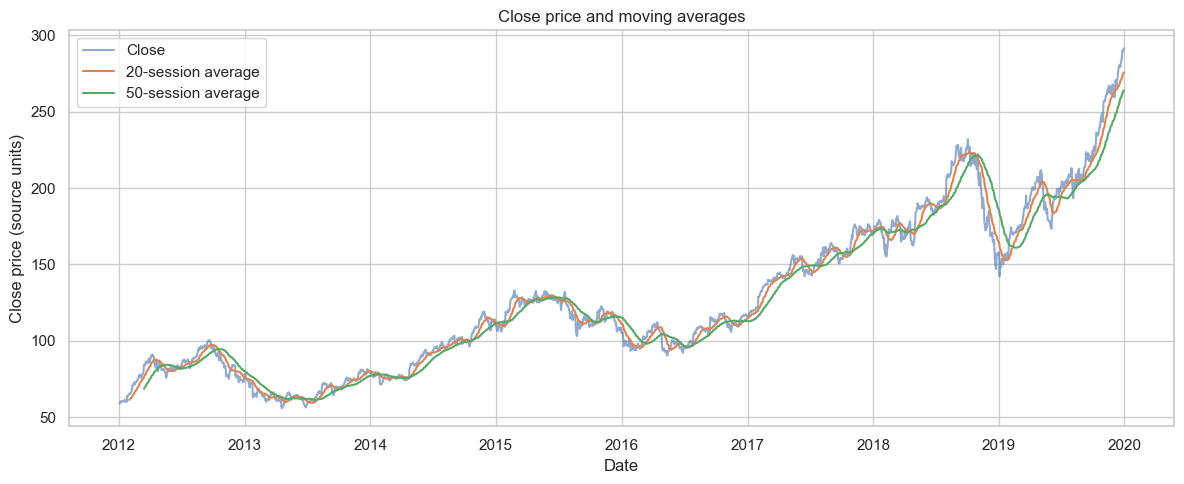

In [16]:
df["Close_MA_20"] = df["Close"].rolling(20).mean()
df["Close_MA_50"] = df["Close"].rolling(50).mean()

plt.figure(figsize=(12, 5))
plt.plot(df["Date_parsed"], df["Close"], label="Close", alpha=0.6)
plt.plot(df["Date_parsed"], df["Close_MA_20"], label="20-session average")
plt.plot(df["Date_parsed"], df["Close_MA_50"], label="50-session average")
plt.title("Close price and moving averages")
plt.xlabel("Date")
plt.ylabel("Close price (source units)")
plt.legend()
plt.tight_layout()
plt.show()

**Observation:** The moving averages smooth the price series and follow its broad rise, with a delay when the direction changes.

## 12. Rolling return variability

The rolling standard deviation summarizes recent daily return variability over 20 observations. It is shown in percentage points per session and is not annualized.

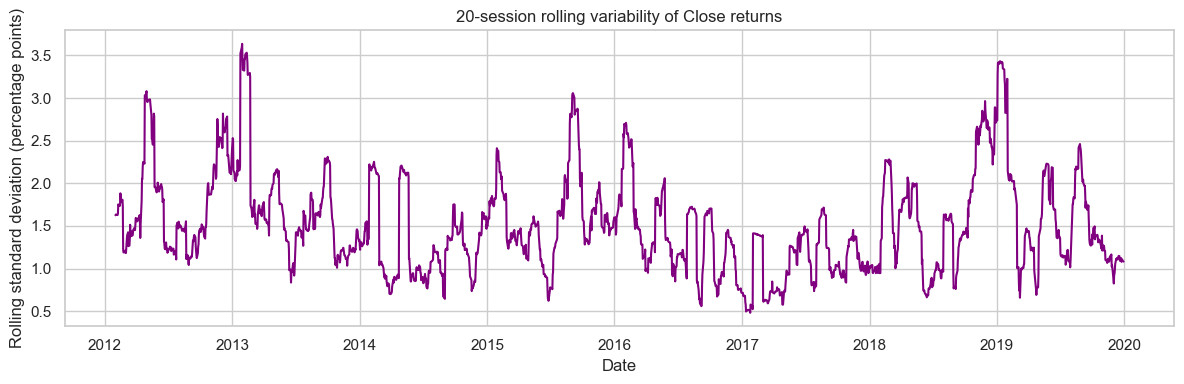

Highest rolling variability: 3.6364607398171422


In [17]:
df["Return_Volatility_20"] = df["Daily_Return"].rolling(20).std()

plt.figure(figsize=(12, 4))
plt.plot(df["Date_parsed"], df["Return_Volatility_20"], color="purple")
plt.title("20-session rolling variability of Close returns")
plt.xlabel("Date")
plt.ylabel("Rolling standard deviation (percentage points)")
plt.tight_layout()
plt.show()

print("Highest rolling variability:", df["Return_Volatility_20"].max())

**Observation:** Return variability changes over time, with periods of elevated variability separated by calmer periods.

## 13. Calendar summaries

Compare changes within each calendar year and average monthly returns. The first-to-last yearly change excludes the return into the first observation of that year; monthly returns use consecutive month-end closes. These descriptions do not establish seasonality.

             Change_pct
Date_parsed            
2012          29.409330
2013           2.183855
2014          39.688680
2015          -3.722674
2016           9.938303
2017          45.699521
2018          -8.429113
2019          84.599793


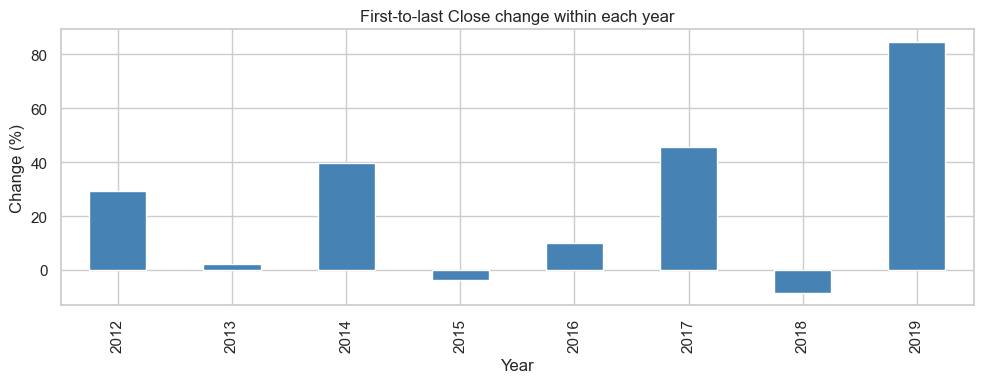

In [18]:
yearly_close = df.groupby(df["Date_parsed"].dt.year)["Close"].agg(["first", "last"])
yearly_close["Change_pct"] = (yearly_close["last"] / yearly_close["first"] - 1) * 100
print(yearly_close[["Change_pct"]])

yearly_close["Change_pct"].plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("First-to-last Close change within each year")
plt.xlabel("Year")
plt.ylabel("Change (%)")
plt.tight_layout()
plt.show()

**Observation:** The within-year Close change is negative in 2015 and 2018 and positive in the other displayed years. This summary does not establish a recurring annual pattern.

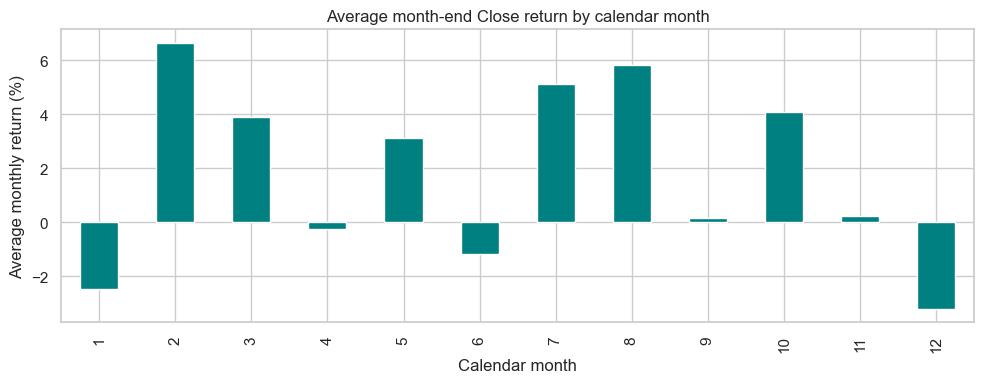

Date_parsed
1    -2.48
2     6.64
3     3.89
4    -0.24
5     3.13
6    -1.20
7     5.12
8     5.81
9     0.15
10    4.07
11    0.23
12   -3.21
Name: Close, dtype: float64


In [19]:
monthly_close = df.groupby(df["Date_parsed"].dt.to_period("M"))["Close"].last()
monthly_return = monthly_close.pct_change() * 100
monthly_average = monthly_return.groupby(monthly_return.index.month).mean()

monthly_average.plot(kind="bar", figsize=(10, 4), color="teal")
plt.title("Average month-end Close return by calendar month")
plt.xlabel("Calendar month")
plt.ylabel("Average monthly return (%)")
plt.tight_layout()
plt.show()
print(monthly_average.round(2))

**Observation:** Average monthly returns vary across calendar months in this sample. The limited historical period does not establish a reliable seasonal effect.

## 14. Stationarity diagnostic

The Augmented Dickey-Fuller test checks a unit-root null hypothesis. A small p-value is evidence against that null under the test assumptions; it does not prove that a series or a forecasting model is stable. This full-sample check is descriptive: model diagnostics must be repeated using training data only.

In [20]:
from statsmodels.tsa.stattools import adfuller

close_adf = adfuller(df["Close"], autolag="AIC")
return_adf = adfuller(df["Daily_Return"].dropna(), autolag="AIC")
print("Close ADF statistic:", close_adf[0], "p-value:", close_adf[1])
print("Close return ADF statistic:", return_adf[0], "p-value:", return_adf[1])

Close ADF statistic: 1.2193701254378022 p-value: 0.9961170178032009
Close return ADF statistic: -15.852960945107094 p-value: 9.402165938786095e-29


**Observation:** The Close test has p ≈ 0.996, so it does not reject the unit-root null at 5%. The return test has p < 0.001 and rejects that null at 5%; this does not guarantee stable future behavior.

## 15. Training-only stationarity check

The full-sample ADF check above describes the dataset. For model design, repeat ADF using only observations through 2017. The unit-root null is tested for Close and its first difference; the result does not guarantee future stability.

In [21]:
train_close = df.loc[df["Date_parsed"] < "2018-01-01", "Close"]
train_adf = adfuller(train_close, autolag="AIC")
train_diff_adf = adfuller(train_close.diff().dropna(), autolag="AIC")
print("Training observations:", len(train_close))
print("Close ADF statistic and p-value:", train_adf[0], train_adf[1])
print("First-difference ADF statistic and p-value:", train_diff_adf[0], train_diff_adf[1])

Training observations: 1509
Close ADF statistic and p-value: -0.32802806245803656 0.9214398465747211
First-difference ADF statistic and p-value: -28.083231127962772 0.0


**Observation:** The training-only Close p-value is approximately 0.921; the first-difference p-value is below 0.001. At the 5% level the first test does not reject the unit-root null, while the second does under its assumptions.

## 16. Forecasting design

Use the supplied Close as target. Compare a persistence baseline, ARIMA(1,1,0), exploratory SARIMA(1,1,0)×(0,0,1,5), Random Forest and XGBoost. The five-session seasonal term is a candidate, not established seasonality. Parameters are fixed, with seed 717; no broad tuning is performed.

At each origin, use at most 800 known closes. Validation origins occur in 2018 and test origins in 2019, spaced 50 observed sessions apart. All 30 target sessions stay within the same evaluation year. Earlier validation or test observations can enter later fits only after they have occurred.

In [22]:
HORIZON = 30
LOOKBACK = 20
WINDOW = 800
SEED = 717
MODELS = ("Naive", "ARIMA", "SARIMA", "Random Forest", "XGBoost")
prices = df["Close"].to_numpy(dtype=float)
dates = df["Date_parsed"].reset_index(drop=True)
assert dates.notna().all() and dates.is_monotonic_increasing and not dates.duplicated().any()
assert np.isfinite(prices).all() and (prices > 0).all()
print("Target: supplied Close; horizon:", HORIZON, "trading sessions")
print("Last available date:", dates.iloc[-1].date())

Target: supplied Close; horizon: 30 trading sessions
Last available date: 2019-12-30


## 17. Feature engineering and scaling

The tree models use only trailing log returns, price-to-moving-average ratios and trailing return variability. Their one-step log-return predictions are applied recursively, so later steps use earlier predictions rather than future actual values. The exponential conversion returns every forecast to the Close-price scale.

ARIMA and SARIMA receive Close levels and apply `d=1` internally; prices are not differenced twice. StandardScaler is not needed for these tree models and was not used in the validated ARIMA fits. A future scale-sensitive model would fit its scaler on each training window only.

### Build trailing features

Each feature is calculated using values available at the current forecast step.

In [23]:
def features(prices):
    """Features available after the most recent observed or predicted close."""
    p = np.asarray(prices, dtype=float)
    returns = np.diff(np.log(p))
    return np.array([returns[-1], returns[-2], returns[-3], returns[-5],
                     returns[-10], p[-1] / p[-5:].mean() - 1,
                     p[-1] / p[-20:].mean() - 1, returns[-20:].std()])

### Fit each candidate

The naïve model needs no fitting. The statistical models receive Close levels; the trees learn the next log return from earlier prices.

In [24]:
def fit_model(name, prices):
    prices = np.asarray(prices, dtype=float)[-WINDOW:]
    if name == "Naive":
        return None
    if name == "ARIMA":
        return ARIMA(prices, order=(1, 1, 0)).fit()
    if name == "SARIMA":
        # Five sessions is an exploratory weekly candidate, not proven seasonality.
        return SARIMAX(prices, order=(1, 1, 0), seasonal_order=(0, 0, 1, 5),
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=40)
    rows, targets = [], []
    for end in range(LOOKBACK + 1, len(prices)):
        rows.append(features(prices[:end]))
        targets.append(np.log(prices[end] / prices[end - 1]))
    if name == "Random Forest":
        model = RandomForestRegressor(n_estimators=80, max_depth=6, min_samples_leaf=5,
                                      random_state=SEED, n_jobs=1)
    elif name == "XGBoost":
        model = XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.05,
                             subsample=1, colsample_bytree=1, n_jobs=1,
                             random_state=SEED, objective="reg:squarederror")
    else:
        raise ValueError(f"Unknown model: {name}")
    return model.fit(np.asarray(rows), np.asarray(targets))

### Forecast 30 sessions

For trees, append each predicted Close before calculating the next step. No actual future OHLC or Close values enter this process.

In [25]:
def forecast(name, model, history, horizon=HORIZON):
    """Predict the entire horizon without seeing actual future values."""
    history = np.asarray(history, dtype=float)
    if name == "Naive":
        return np.repeat(history[-1], horizon)
    if name in ("ARIMA", "SARIMA"):
        return np.asarray(model.forecast(steps=horizon), dtype=float)
    path = list(history[-(LOOKBACK + 1):])
    predictions = []
    for _ in range(horizon):
        next_return = float(model.predict(features(path).reshape(1, -1))[0])
        next_price = path[-1] * np.exp(next_return)
        path.append(next_price)
        predictions.append(next_price)
    return np.asarray(predictions)

## 18. Choose chronological origins

The following origin selection matches the validated experiment. Every target in a forecast must remain inside its assigned year.

In [26]:
def origins_for_year(dates, year):
    candidates = [i for i in range(len(dates) - HORIZON)
                  if dates.iloc[i].year == year and dates.iloc[i + 1].year == year
                  and dates.iloc[i + HORIZON].year == year]
    return candidates[::50]

origins = {"validation": origins_for_year(dates, 2018),
           "test": origins_for_year(dates, 2019)}
for period, positions in origins.items():
    print(period, [str(dates.iloc[i].date()) for i in positions])
    assert len(positions) == 5 and all(i >= WINDOW for i in positions)

validation ['2018-01-02', '2018-03-15', '2018-05-25', '2018-08-07', '2018-10-17']
test ['2019-01-02', '2019-03-15', '2019-05-28', '2019-08-07', '2019-10-17']


## 19. Fit and evaluate the models

Fit all candidates independently at each origin using only the history through that origin. Generate a genuine 30-step path before looking at the next 30 actual prices. This cell takes several minutes on some computers.

In [27]:
results = {}
failures = []
warning_messages = []
for period, positions in origins.items():
    results[period] = {name: [] for name in MODELS}
    for index in positions:
        history = prices[:index + 1].copy()
        actual = prices[index + 1:index + HORIZON + 1].copy()
        for name in MODELS:
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    model = fit_model(name, history)
                    if name in ("ARIMA", "SARIMA") and not model.mle_retvals.get("converged", True):
                        raise RuntimeError("optimizer did not converge")
                    predicted = forecast(name, model, history)
                if caught:
                    warning_messages.extend(str(w.message) for w in caught)
                if len(predicted) != HORIZON or not np.isfinite(predicted).all():
                    raise ValueError("Invalid forecast")
                results[period][name].append({"index": index, "actual": actual, "prediction": predicted})
            except Exception as exc:
                failures.append((period, str(dates.iloc[index].date()), name, str(exc)))
        print(period, dates.iloc[index].date(), "completed")
print("Failed evaluations:", len(failures))
print("Captured nonfatal warnings:", len(warning_messages))
if failures:
    raise RuntimeError(f"Forecast evaluations failed: {failures}")

validation 2018-01-02 completed
validation 2018-03-15 completed
validation 2018-05-25 completed
validation 2018-08-07 completed
validation 2018-10-17 completed
test 2019-01-02 completed
test 2019-03-15 completed
test 2019-05-28 completed
test 2019-08-07 completed
test 2019-10-17 completed
Failed evaluations: 0
Captured nonfatal warnings: 20


validation 2018-03-15 completed


validation 2018-05-25 completed


validation 2018-08-07 completed


validation 2018-10-17 completed


test 2019-01-02 completed


test 2019-03-15 completed


test 2019-05-28 completed


test 2019-08-07 completed


test 2019-10-17 completed
Failed evaluations: 0
Captured nonfatal warnings: 20


## 20. Calculate MAE and RMSE

Calculate errors on the original Close scale across all 30 steps and all five origins in each period. Step-30 MAE summarizes the final step separately; improvement compares pooled MAE with the naïve baseline.

In [28]:
def error_metrics(actual, predicted):
    error = np.asarray(predicted) - np.asarray(actual)
    return {"mae": float(np.mean(np.abs(error))),
            "rmse": float(np.sqrt(np.mean(error ** 2)))}

summary = {}
comparison_rows = []
for period in ("validation", "test"):
    summary[period] = {}
    for name in MODELS:
        rows = results[period][name]
        assert len(rows) == len(origins[period])
        actual = np.stack([row["actual"] for row in rows])
        predicted = np.stack([row["prediction"] for row in rows])
        summary[period][name] = {"overall": error_metrics(actual, predicted),
                                 "step_30": error_metrics(actual[:, -1], predicted[:, -1])}
    baseline_mae = summary[period]["Naive"]["overall"]["mae"]
    for name in MODELS:
        item = summary[period][name]
        comparison_rows.append({"Period": period, "Model": name,
                                "MAE": item["overall"]["mae"],
                                "RMSE": item["overall"]["rmse"],
                                "Step 30 MAE": item["step_30"]["mae"],
                                "MAE improvement vs naive (%)": 100 * (1 - item["overall"]["mae"] / baseline_mae)})
comparison = pd.DataFrame(comparison_rows)
comparison.round(3)

,Period,Model,MAE,RMSE,Step 30 MAE,MAE improvement vs naive (%)
0,validation,Naive,9.799,14.335,15.178,0.000
1,validation,ARIMA,9.827,14.351,15.216,-0.295
2,validation,SARIMA,9.824,14.345,15.187,-0.257
3,validation,Random Forest,12.434,17.840,24.619,-26.893
4,validation,XGBoost,10.313,14.822,16.606,-5.250
5,test,Naive,13.476,16.012,22.052,0.000
6,test,ARIMA,13.460,16.001,22.034,0.121
7,test,SARIMA,13.532,16.027,21.959,-0.413
8,test,Random Forest,11.628,14.503,14.277,13.718
9,test,XGBoost,11.036,13.219,16.522,18.110


## 21. Validation-based selection and reproducibility

Choose the lowest pooled validation MAE, before consulting test scores. Compare the computed metrics with the previously verified three-decimal reference; this check uses recorded aggregate numbers and does not load saved predictions.

In [29]:
reference = {
    "validation": {"Naive": (9.799, 14.335), "ARIMA": (9.827, 14.351),
                   "SARIMA": (9.824, 14.345), "Random Forest": (12.434, 17.840),
                   "XGBoost": (10.313, 14.822)},
    "test": {"Naive": (13.476, 16.012), "ARIMA": (13.460, 16.001),
             "SARIMA": (13.532, 16.027), "Random Forest": (11.628, 14.503),
             "XGBoost": (11.036, 13.219)}}
for period in reference:
    for name, (ref_mae, ref_rmse) in reference[period].items():
        calculated = summary[period][name]["overall"]
        assert abs(calculated["mae"] - ref_mae) < 0.00051
        assert abs(calculated["rmse"] - ref_rmse) < 0.00051
selected = min(MODELS, key=lambda name: summary["validation"][name]["overall"]["mae"])
print("Reference metrics match to three decimals:", True)
print("Validation-selected model:", selected)

Reference metrics match to three decimals: True
Validation-selected model: Naive


**Observation:** The naïve baseline has the lowest validation MAE and is selected. XGBoost and Random Forest have lower test MAE in this sample, but the held-out test was not used to change the selection.

## 22. Visualize model errors

Compare pooled MAE for each model in validation and test. The two periods are shown separately because model selection is based only on validation.

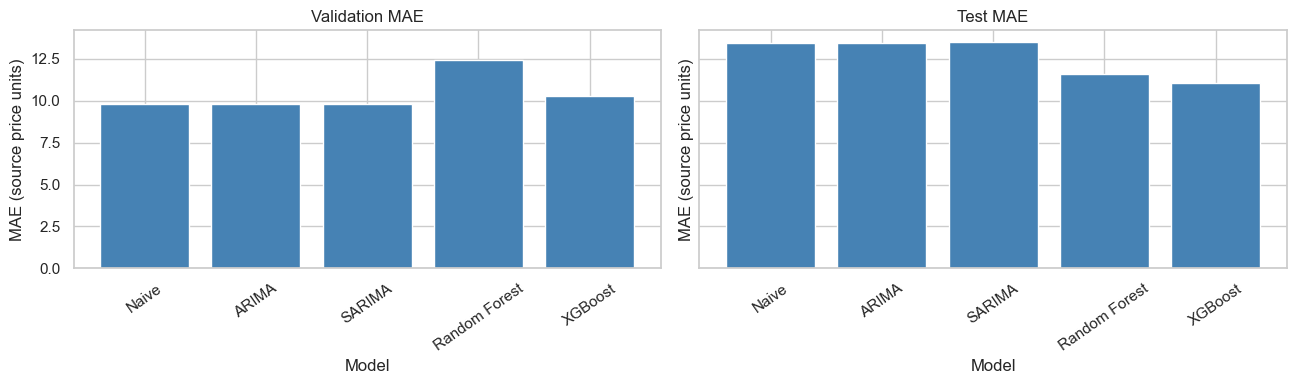

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, period in zip(axes, ["validation", "test"]):
    subset = comparison.loc[comparison["Period"] == period]
    ax.bar(subset["Model"], subset["MAE"], color="steelblue")
    ax.set_title(period.title() + " MAE")
    ax.set_xlabel("Model")
    ax.set_ylabel("MAE (source price units)")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 23. Historical forecast versus actual Close

Display the last evaluated test origin, 2019-10-17. The selected naïve path and ARIMA comparison were generated before observing the next 30 sessions.

Forecast origin: 2019-10-17
Forecast dates: 2019-10-18 to 2019-11-29


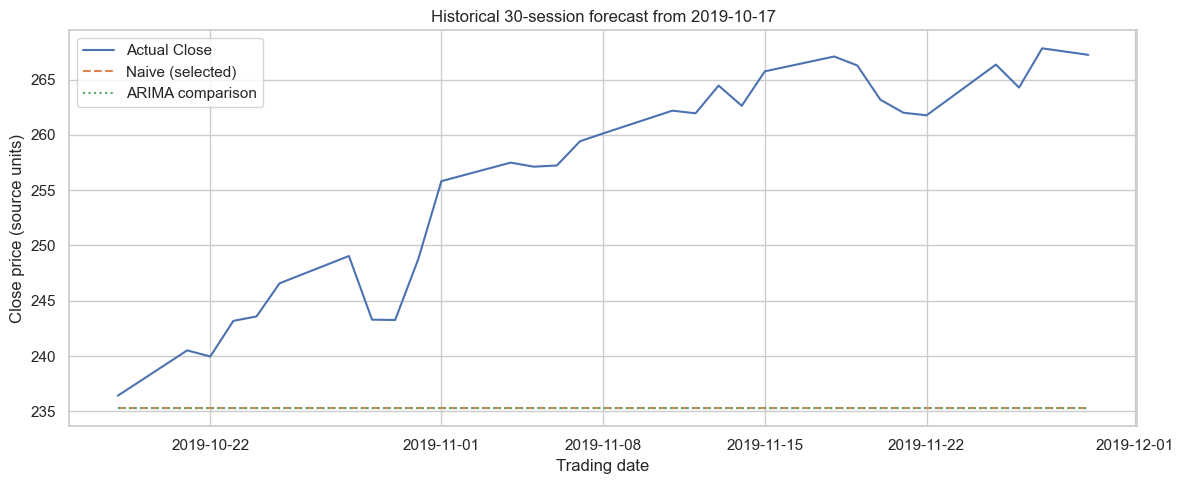

In [31]:
selected_row = results["test"][selected][-1]
arima_row = results["test"]["ARIMA"][-1]
origin_index = selected_row["index"]
assert arima_row["index"] == origin_index
forecast_dates = dates.iloc[origin_index + 1:origin_index + HORIZON + 1]
print("Forecast origin:", dates.iloc[origin_index].date())
print("Forecast dates:", forecast_dates.iloc[0].date(), "to", forecast_dates.iloc[-1].date())
plt.figure(figsize=(12, 5))
plt.plot(forecast_dates, selected_row["actual"], label="Actual Close")
plt.plot(forecast_dates, selected_row["prediction"], "--", label="Naive (selected)")
plt.plot(forecast_dates, arima_row["prediction"], ":", label="ARIMA comparison")
plt.title("Historical 30-session forecast from 2019-10-17")
plt.xlabel("Trading date")
plt.ylabel("Close price (source units)")
plt.legend()
plt.tight_layout()
plt.show()

## 24. Findings, limitations and recommendations

The supplied series is complete and chronological; its Close and Adj Close differ. Training-only ADF results support examining one difference, but stationarity and seasonal behavior are not guaranteed. The simple naïve baseline wins the fixed validation comparison, so added complexity is not automatically justified.

The sample ends in 2019, uses only five origins per evaluation period and cannot reflect later events. Confirm the 30-trading-session interpretation and the source adjustment policy. For future work, collect appropriately licensed recent data and repeat the same leak-free evaluation before considering live use. The demo shows historical results and requires separate permission before sharing derived artifacts.